# **1. Import Libraries and Data Exploration**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_excel("/content/credit card_dataset.xlsx")
df.head()

,Gender,Age,Debt,Married,BankCustomer,Industry,Ethnicity,YearsEmployed,PriorDefault,Employed,CreditScore,DriversLicense,Citizen,ZipCode,Income,Approved
0,1,30.83,0.000,1,1,Industrials,White,1.25,1,1,1,0,ByBirth,202,0,1
1,0,58.67,4.460,1,1,Materials,Black,3.04,1,1,6,0,ByBirth,43,560,1
2,0,24.50,0.500,1,1,Materials,Black,1.50,1,0,0,0,ByBirth,280,824,1
3,1,27.83,1.540,1,1,Industrials,White,3.75,1,1,5,1,ByBirth,100,3,1
4,1,20.17,5.625,1,1,Industrials,White,1.71,1,0,0,0,ByOtherMeans,120,0,1


In [ ]:
df.shape

(690, 16)

In [ ]:
df.columns

Index(['Gender', 'Age', 'Debt', 'Married', 'BankCustomer', 'Industry',
       'Ethnicity', 'YearsEmployed', 'PriorDefault', 'Employed', 'CreditScore',
       'DriversLicense', 'Citizen', 'ZipCode', 'Income', 'Approved'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Gender          690 non-null    int64  
 1   Age             690 non-null    float64
 2   Debt            690 non-null    float64
 3   Married         690 non-null    int64  
 4   BankCustomer    690 non-null    int64  
 5   Industry        690 non-null    object 
 6   Ethnicity       690 non-null    object 
 7   YearsEmployed   690 non-null    float64
 8   PriorDefault    690 non-null    int64  
 9   Employed        690 non-null    int64  
 10  CreditScore     690 non-null    int64  
 11  DriversLicense  690 non-null    int64  
 12  Citizen         690 non-null    object 
 13  ZipCode         690 non-null    int64  
 14  Income          690 non-null    int64  
 15  Approved        690 non-null    int64  
dtypes: float64(3), int64(10), object(3)
memory usage: 86.4+ KB


In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df.duplicated().sum()

np.int64(0)

# **2. Pre-Processing ( Needed before EDA)**

In [ ]:
df = df.drop(
    columns=['ZipCode']
)

df.head()

,Gender,Age,Debt,Married,BankCustomer,Industry,Ethnicity,YearsEmployed,PriorDefault,Employed,CreditScore,DriversLicense,Citizen,Income,Approved
0,1,30.83,0.000,1,1,Industrials,White,1.25,1,1,1,0,ByBirth,0,1
1,0,58.67,4.460,1,1,Materials,Black,3.04,1,1,6,0,ByBirth,560,1
2,0,24.50,0.500,1,1,Materials,Black,1.50,1,0,0,0,ByBirth,824,1
3,1,27.83,1.540,1,1,Industrials,White,3.75,1,1,5,1,ByBirth,3,1
4,1,20.17,5.625,1,1,Industrials,White,1.71,1,0,0,0,ByOtherMeans,0,1


In [ ]:
df['Industry'].value_counts()

,count
Industry,
Energy,146
Materials,78
Industrials,64
ConsumerDiscretionary,59
ConsumerStaples,54
Healthcare,53
Financials,51
InformationTechnology,41
Utilities,38


In [ ]:
print(df['Citizen'].unique())
print(df['Citizen'].value_counts())

['ByBirth' 'ByOtherMeans' 'Temporary']
Citizen
ByBirth         625
ByOtherMeans     57
Temporary         8
Name: count, dtype: int64


In [ ]:
industry_groups = {

    'Energy': 'Resource',

    'Materials': 'Resource',

    'Industrials': 'Industrial',
    'Transport': 'Industrial',

    'InformationTechnology': 'Technology',
    'CommunicationServices': 'Technology',

    'Financials': 'Services',
    'Healthcare': 'Services',
    'Education': 'Services',
    'Research': 'Services',
    'Real Estate': 'Services',

    'ConsumerDiscretionary': 'Consumer',
    'ConsumerStaples': 'Consumer',

    'Utilities': 'Utilities'
}

In [ ]:
df['Industry_Group'] = df['Industry'].map(industry_groups)

df[['Industry', 'Industry_Group']]

,Industry,Industry_Group
0,Industrials,Industrial
1,Materials,Resource
2,Materials,Resource
3,Industrials,Industrial
4,Industrials,Industrial
...,...,...
685,Education,Services
686,Energy,Resource
687,Healthcare,Services
688,ConsumerStaples,Consumer


In [ ]:
print("Original number of Industry classes:",
      df['Industry'].nunique())

print("Number of grouped Industry classes:",
      df['Industry_Group'].nunique())

print("Number of observations is each class:", df['Industry_Group'].value_counts())

Original number of Industry classes: 14
Number of grouped Industry classes: 6
Number of observations is each class: Industry_Group
Resource      224
Services      169
Consumer      113
Technology     79
Industrial     67
Utilities      38
Name: count, dtype: int64


In [ ]:
print(df['Ethnicity'].unique())
print(df['Ethnicity'].value_counts())

['White' 'Black' 'Asian' 'Latino' 'Other']
Ethnicity
White     408
Black     138
Asian      59
Latino     57
Other      28
Name: count, dtype: int64


In [ ]:
df.drop(columns=['Industry'], inplace=True)

In [ ]:
df.head(2)

,Gender,Age,Debt,Married,BankCustomer,Ethnicity,YearsEmployed,PriorDefault,Employed,CreditScore,DriversLicense,Citizen,Income,Approved,Industry_Group
0,1,30.83,0.00,1,1,White,1.25,1,1,1,0,ByBirth,0,1,Industrial
1,0,58.67,4.46,1,1,Black,3.04,1,1,6,0,ByBirth,560,1,Resource


In [ ]:
print(df['Approved'].value_counts())

print(df['Approved'].value_counts(normalize=True) * 100)

Approved
0    383
1    307
Name: count, dtype: int64
Approved
0    55.507246
1    44.492754
Name: proportion, dtype: float64


# **3. EDA**

In [ ]:
numerical_columns = [
    'Age',
    'Debt',
    'YearsEmployed',
    'CreditScore',
    'Income'
]

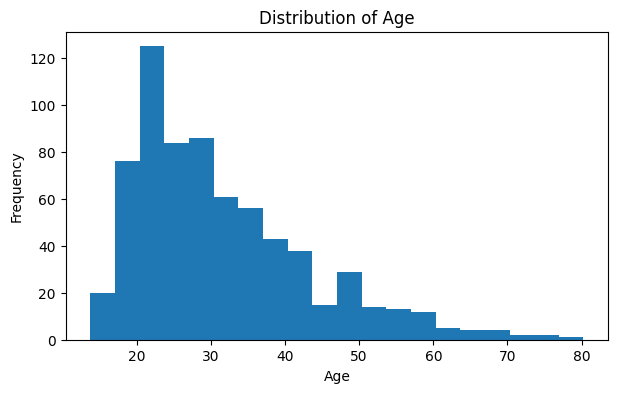

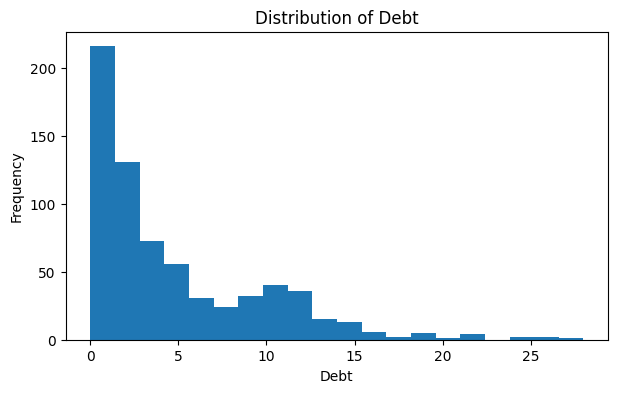

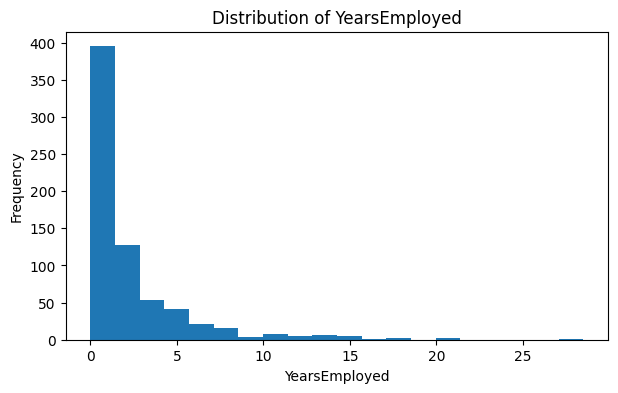

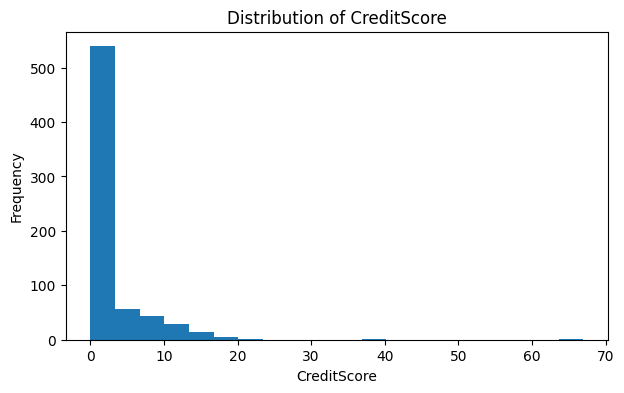

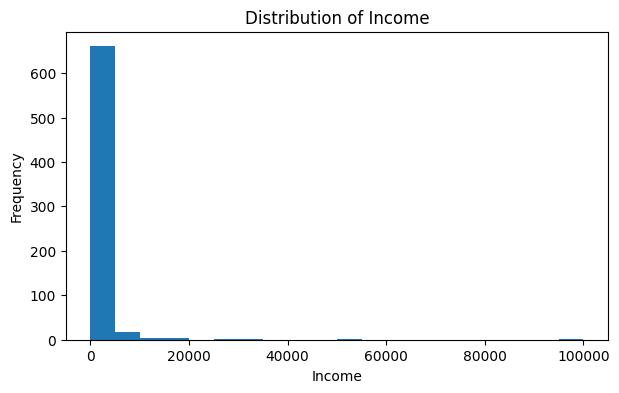

In [ ]:
for column in numerical_columns:

    plt.figure(figsize=(7, 4))

    plt.hist(df[column], bins=20)

    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')

    plt.show()

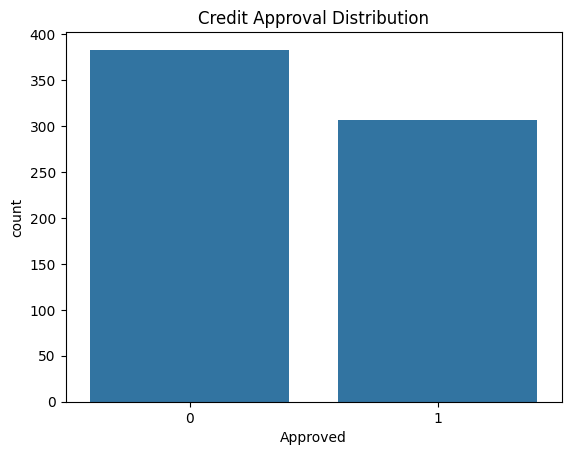

In [ ]:
sns.countplot(x='Approved', data=df)
plt.title('Credit Approval Distribution')
plt.show()

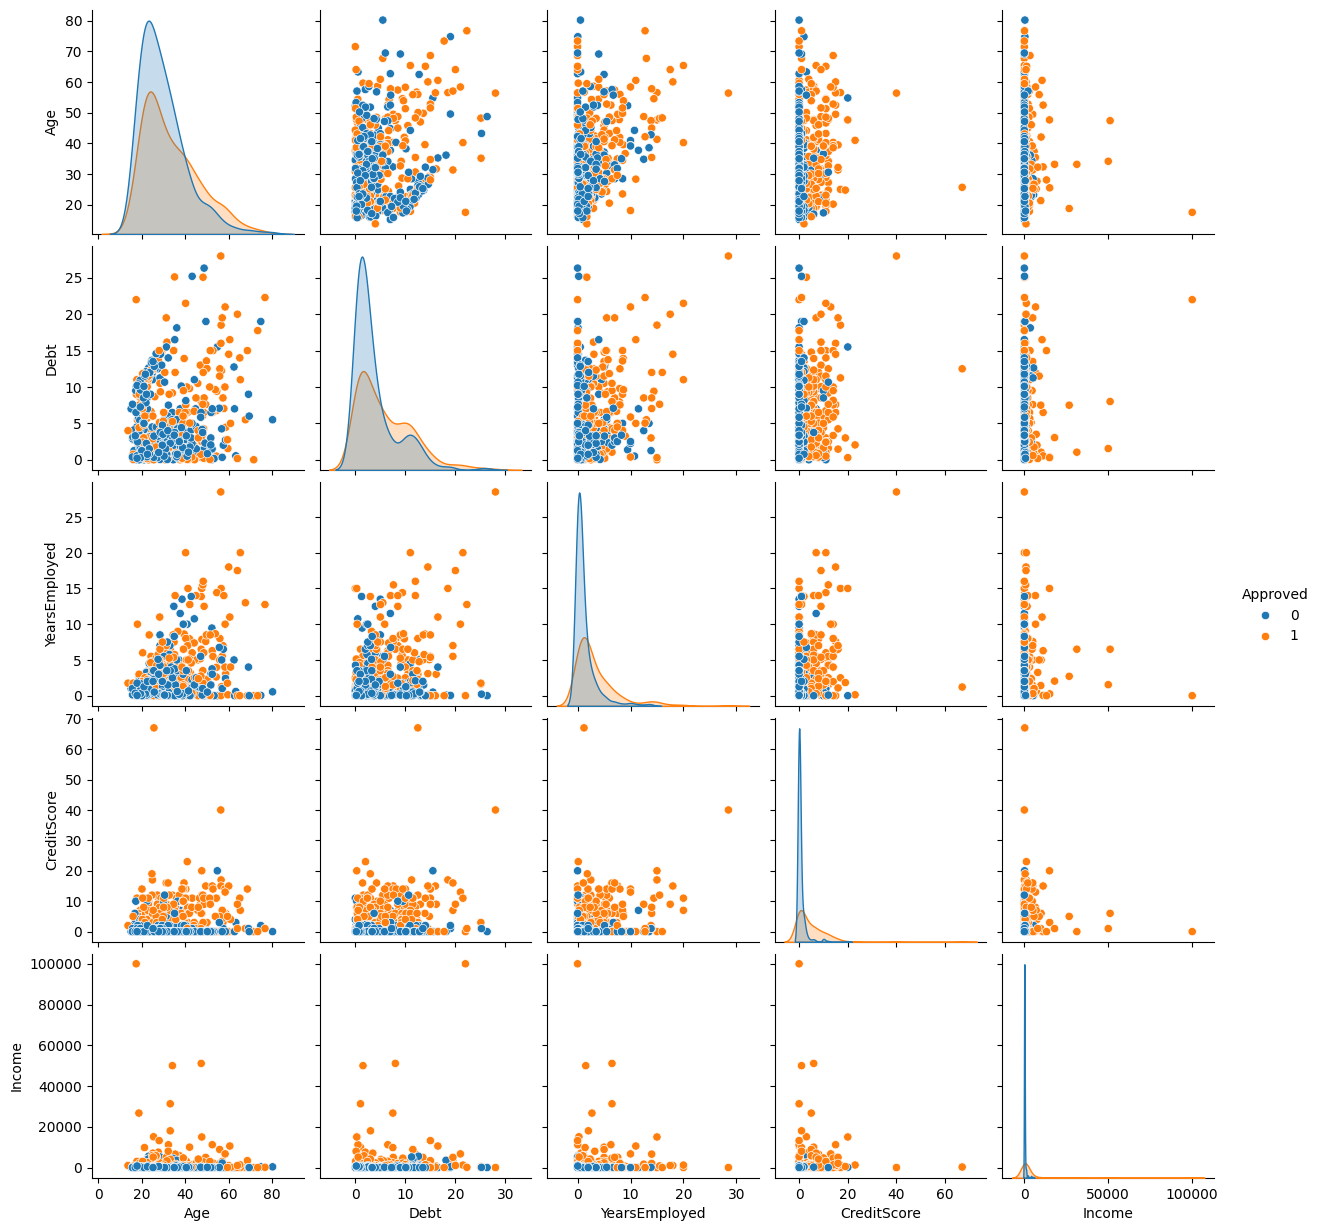

In [ ]:
selected_columns = [
    'Age',
    'Debt',
    'YearsEmployed',
    'CreditScore',
    'Income',
    'Approved'
]

sns.pairplot(
    df[selected_columns],
    hue='Approved'
)

plt.show()

In [ ]:
df.columns

Index(['Gender', 'Age', 'Debt', 'Married', 'BankCustomer', 'Ethnicity',
       'YearsEmployed', 'PriorDefault', 'Employed', 'CreditScore',
       'DriversLicense', 'Citizen', 'Income', 'Approved', 'Industry_Group'],
      dtype='object')

In [ ]:
df['PriorDefault'].unique()

array([1, 0])

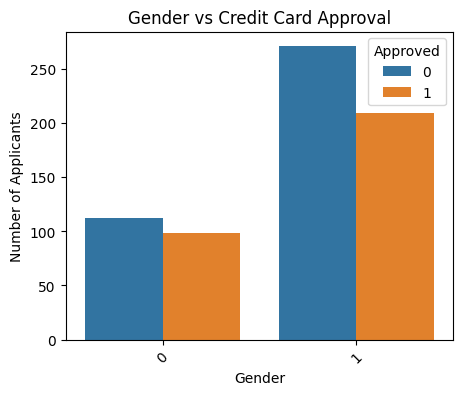

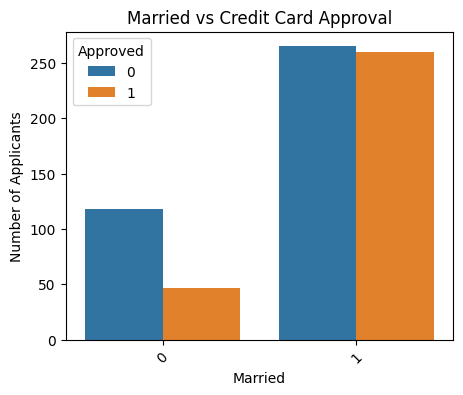

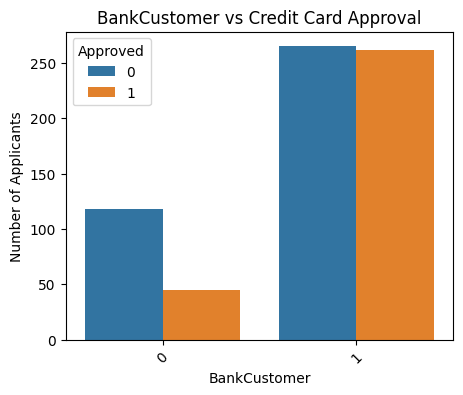

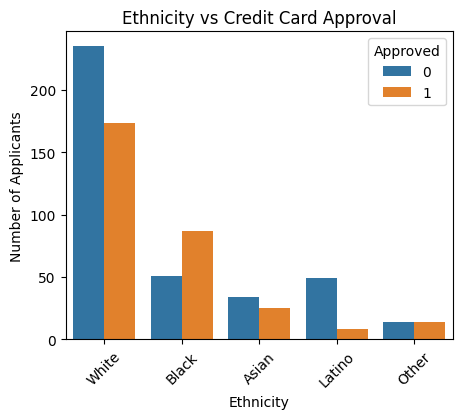

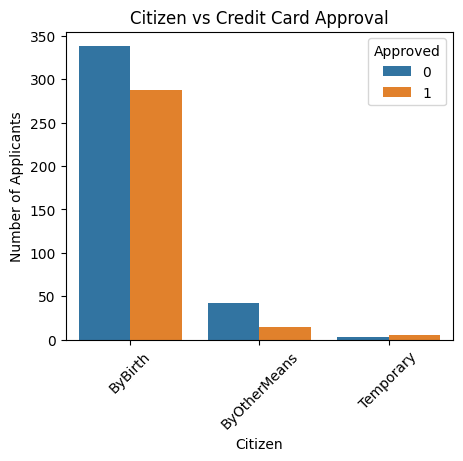

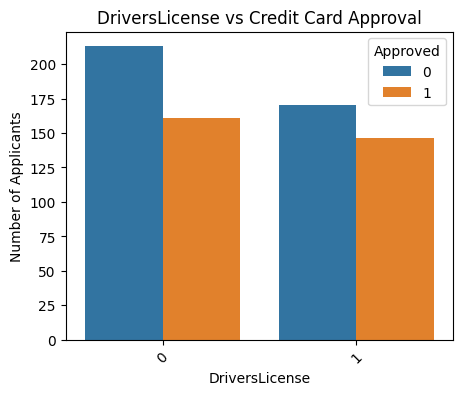

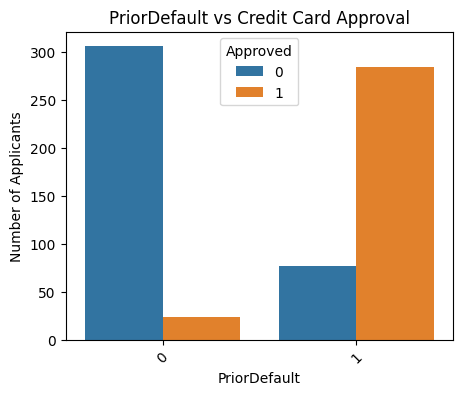

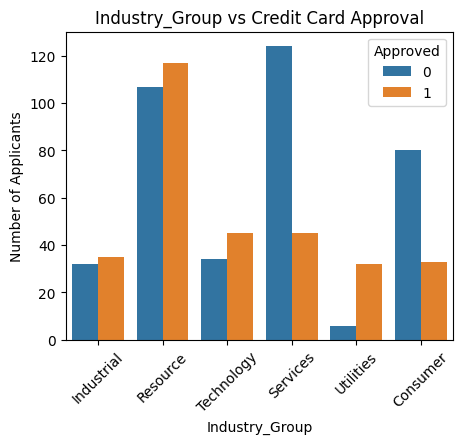

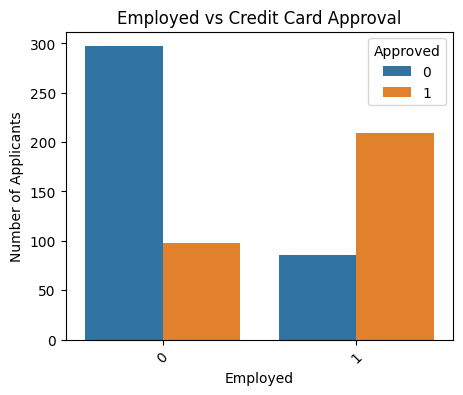

In [ ]:
categorical_columns = [
    'Gender',
    'Married',
    'BankCustomer',
    'Ethnicity',
    'Citizen',
    'DriversLicense',
    'PriorDefault',
    'Industry_Group',
    'Employed'
]

for column in categorical_columns:

    plt.figure(figsize=(5,4))

    sns.countplot(
        data=df,
        x=column,
        hue='Approved'
    )

    plt.title(f'{column} vs Credit Card Approval')
    plt.xlabel(column)
    plt.ylabel('Number of Applicants')

    plt.xticks(rotation=45)

    plt.show()

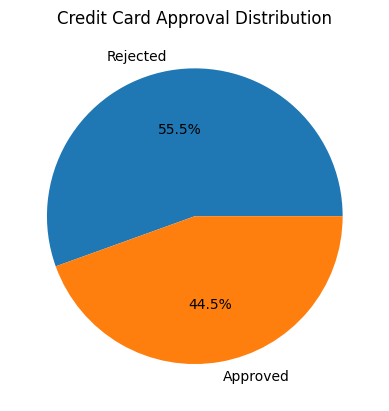

In [ ]:
df['Approved'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    labels=['Rejected', 'Approved']
)

plt.title('Credit Card Approval Distribution')
plt.ylabel('')
plt.show()

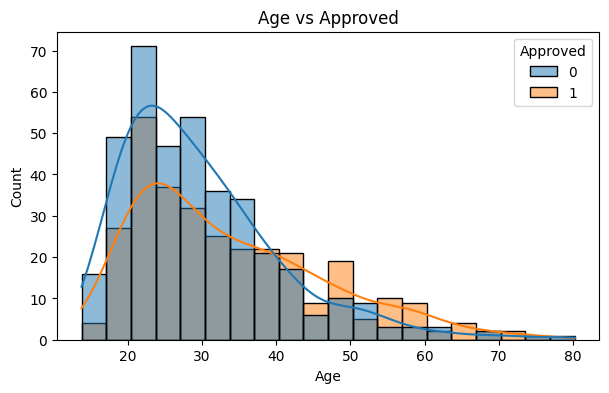

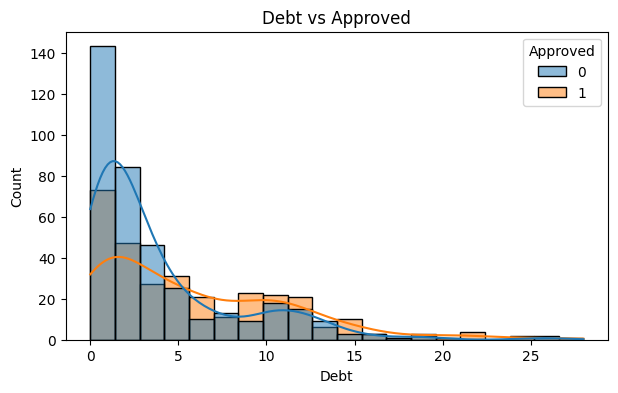

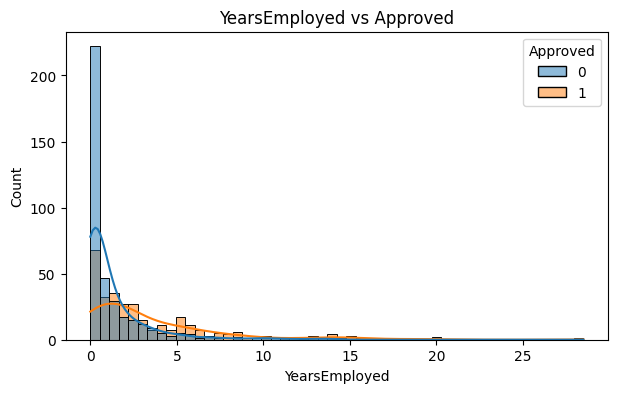

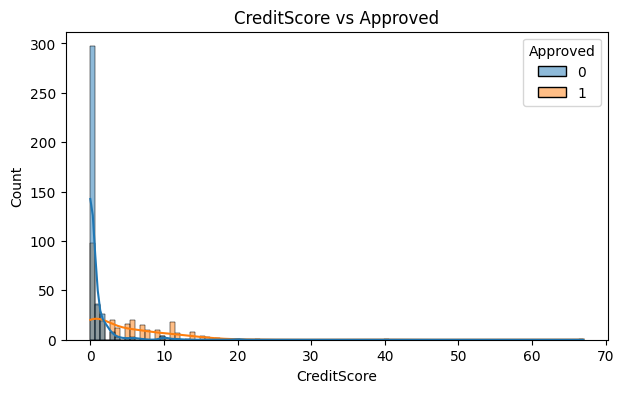

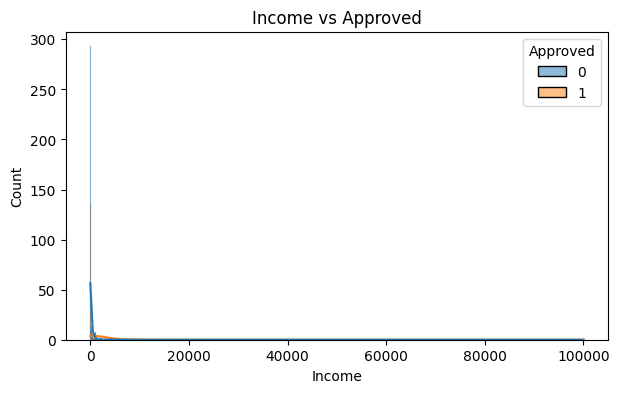

In [ ]:
for col in numerical_columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, hue='Approved', kde=True)
    plt.title(col + ' vs Approved')
    plt.show()

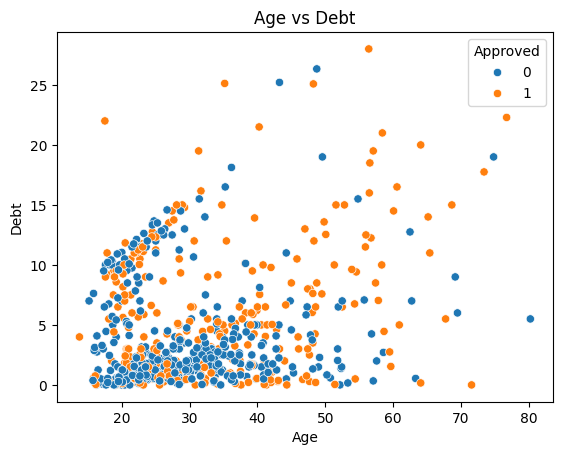

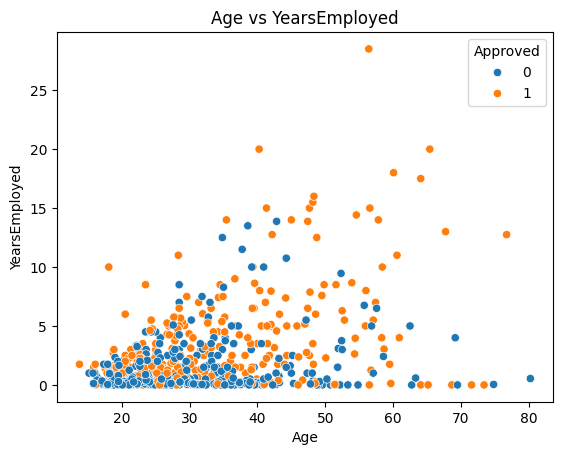

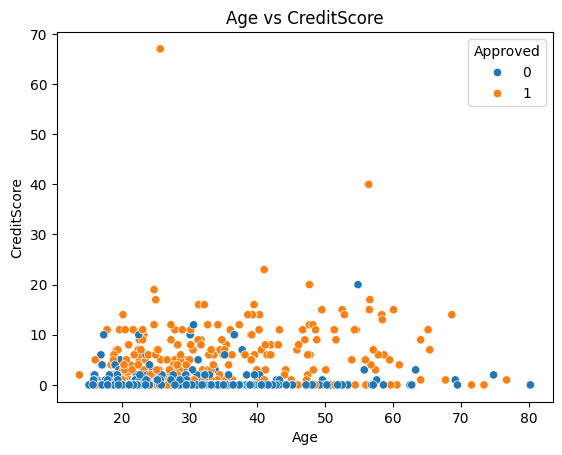

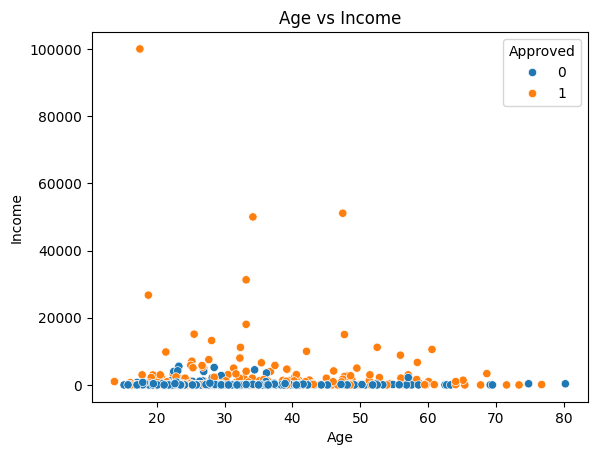

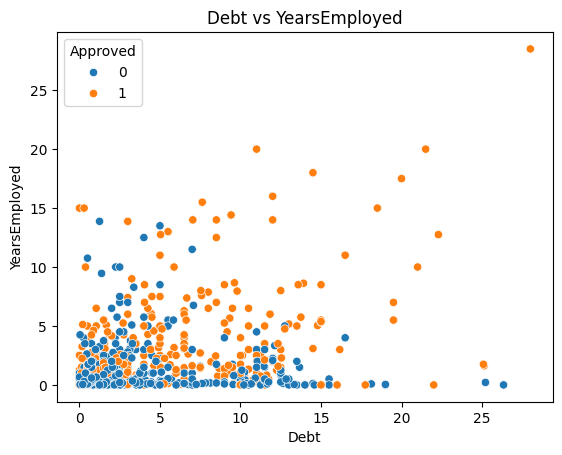

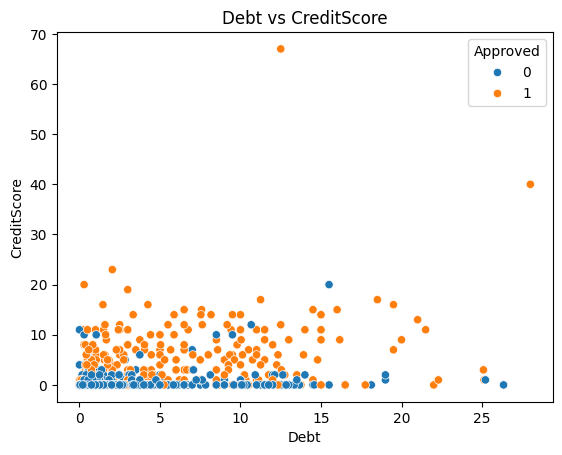

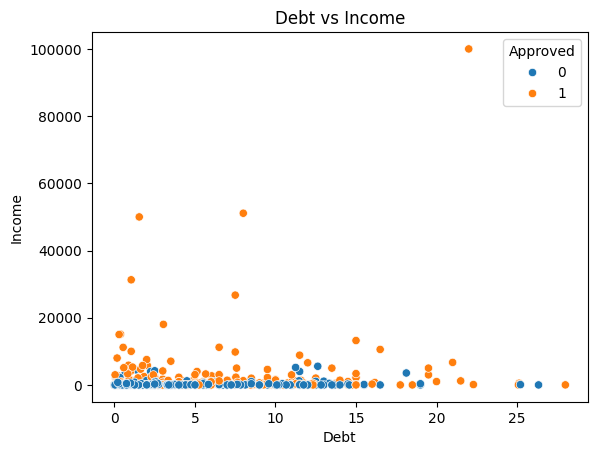

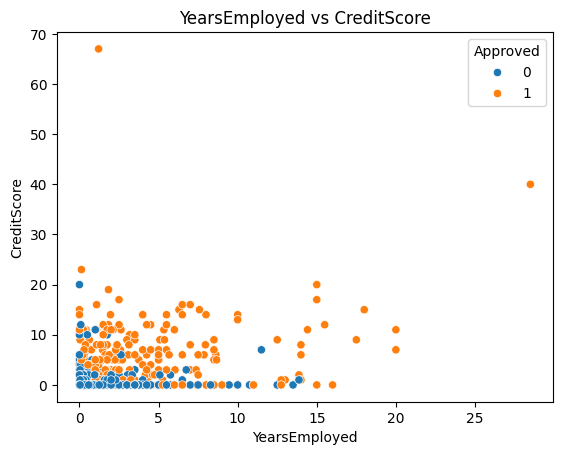

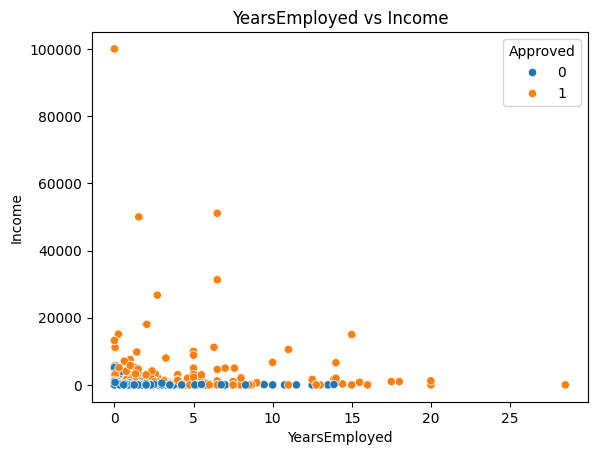

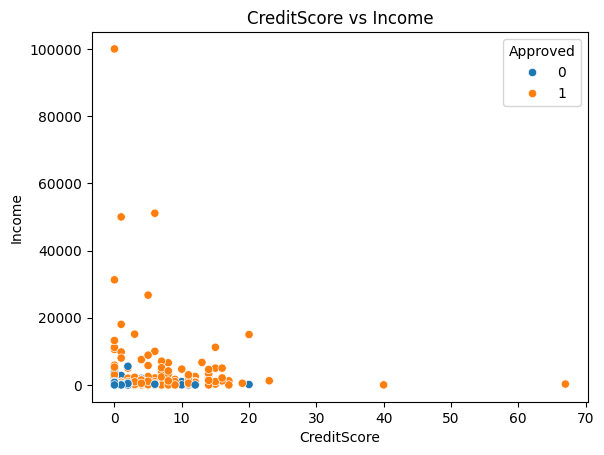

In [ ]:
num_cols = ['Age', 'Debt', 'YearsEmployed', 'CreditScore', 'Income']

for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        sns.scatterplot(data=df, x=num_cols[i], y=num_cols[j], hue='Approved')
        plt.title(f'{num_cols[i]} vs {num_cols[j]}')
        plt.show()

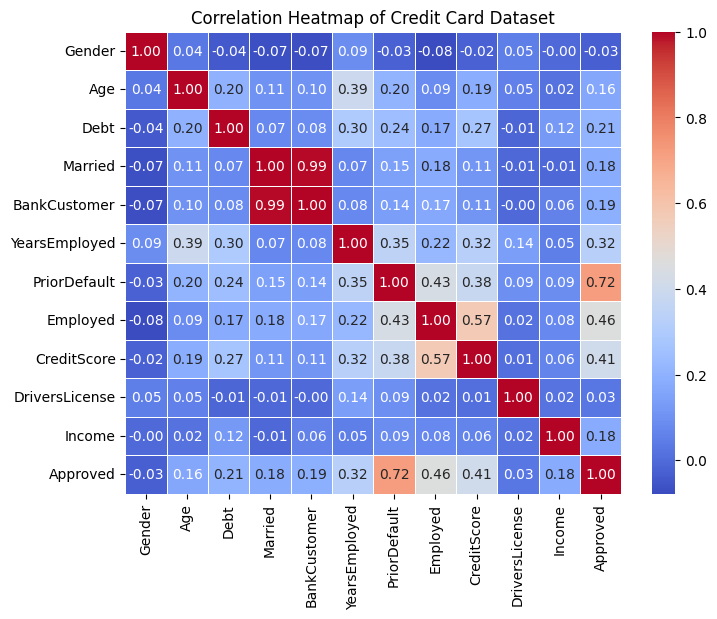

In [ ]:
# Calculate correlation matrix
correlation_matrix = df.corr(numeric_only=True)

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Credit Card Dataset')
plt.show()

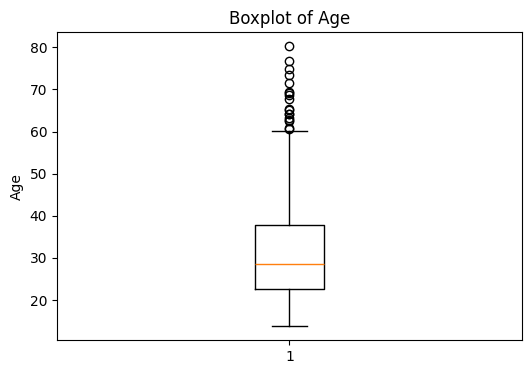

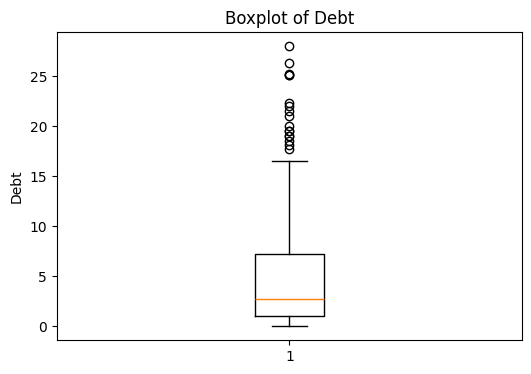

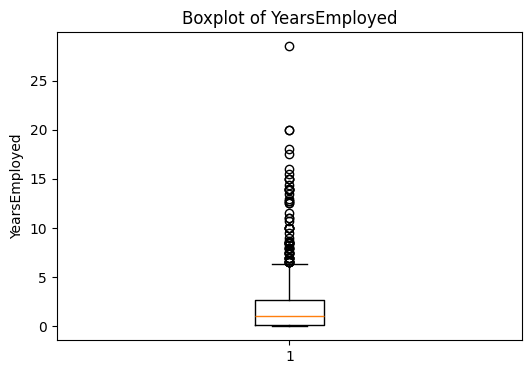

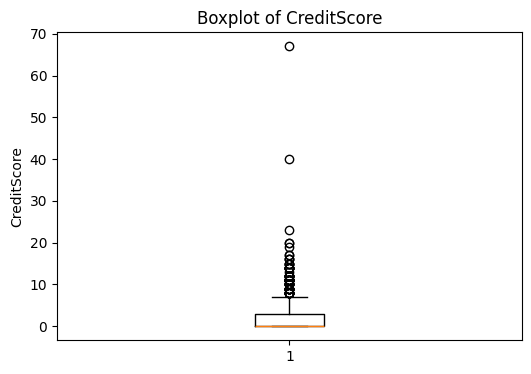

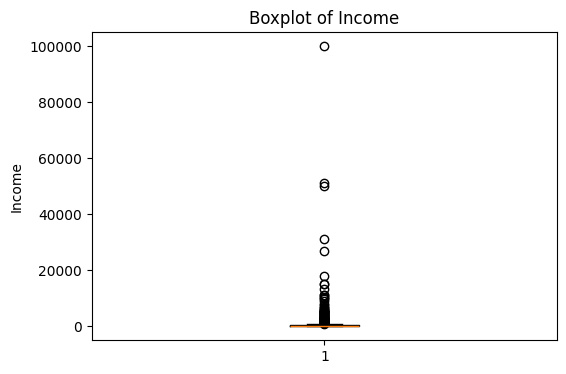

In [ ]:
numerical_columns = [
    'Age',
    'Debt',
    'YearsEmployed',
    'CreditScore',
    'Income'
]

for column in numerical_columns:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[column])
    plt.title(f'Boxplot of {column}')
    plt.ylabel(column)
    plt.show()

In [ ]:
df.describe()


,Gender,Age,Debt,Married,BankCustomer,YearsEmployed,PriorDefault,Employed,CreditScore,DriversLicense,Income,Approved
count,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.00000,690.000000,690.000000,690.000000
mean,0.695652,31.514116,4.758725,0.760870,0.763768,2.223406,0.523188,0.427536,2.40000,0.457971,1017.385507,0.444928
std,0.460464,11.860245,4.978163,0.426862,0.425074,3.346513,0.499824,0.495080,4.86294,0.498592,5210.102598,0.497318
min,0.000000,13.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,0.000000,22.670000,1.000000,1.000000,1.000000,0.165000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
50%,1.000000,28.460000,2.750000,1.000000,1.000000,1.000000,1.000000,0.000000,0.00000,0.000000,5.000000,0.000000
75%,1.000000,37.707500,7.207500,1.000000,1.000000,2.625000,1.000000,1.000000,3.00000,1.000000,395.500000,1.000000
max,1.000000,80.250000,28.000000,1.000000,1.000000,28.500000,1.000000,1.000000,67.00000,1.000000,100000.000000,1.000000


In [ ]:
df.head()

,Gender,Age,Debt,Married,BankCustomer,Ethnicity,YearsEmployed,PriorDefault,Employed,CreditScore,DriversLicense,Citizen,Income,Approved,Industry_Group
0,1,30.83,0.000,1,1,White,1.25,1,1,1,0,ByBirth,0,1,Industrial
1,0,58.67,4.460,1,1,Black,3.04,1,1,6,0,ByBirth,560,1,Resource
2,0,24.50,0.500,1,1,Black,1.50,1,0,0,0,ByBirth,824,1,Resource
3,1,27.83,1.540,1,1,White,3.75,1,1,5,1,ByBirth,3,1,Industrial
4,1,20.17,5.625,1,1,White,1.71,1,0,0,0,ByOtherMeans,0,1,Industrial


# **4. PRE-PROCESSING ( Encoding )**

In [ ]:
df = pd.get_dummies(
    df,
    columns=['Industry_Group', 'Ethnicity', 'Citizen'],
    drop_first=True,
    dtype=int
)

In [ ]:
df.head()

,Gender,Age,Debt,Married,BankCustomer,YearsEmployed,PriorDefault,Employed,CreditScore,DriversLicense,...,Industry_Group_Resource,Industry_Group_Services,Industry_Group_Technology,Industry_Group_Utilities,Ethnicity_Black,Ethnicity_Latino,Ethnicity_Other,Ethnicity_White,Citizen_ByOtherMeans,Citizen_Temporary
0,1,30.83,0.000,1,1,1.25,1,1,1,0,...,0,0,0,0,0,0,0,1,0,0
1,0,58.67,4.460,1,1,3.04,1,1,6,0,...,1,0,0,0,1,0,0,0,0,0
2,0,24.50,0.500,1,1,1.50,1,0,0,0,...,1,0,0,0,1,0,0,0,0,0
3,1,27.83,1.540,1,1,3.75,1,1,5,1,...,0,0,0,0,0,0,0,1,0,0
4,1,20.17,5.625,1,1,1.71,1,0,0,0,...,0,0,0,0,0,0,0,1,1,0


# **5. MODEL TRAINING & EVALUATION**

In [ ]:
X = df.drop(columns=['Approved'])
y = df['Approved']

In [ ]:
df['Approved'].value_counts()

,count
Approved,
0,383
1,307


In [ ]:
print(X.columns.tolist())

['Gender', 'Age', 'Debt', 'Married', 'BankCustomer', 'YearsEmployed', 'PriorDefault', 'Employed', 'CreditScore', 'DriversLicense', 'Income', 'Industry_Group_Industrial', 'Industry_Group_Resource', 'Industry_Group_Services', 'Industry_Group_Technology', 'Industry_Group_Utilities', 'Ethnicity_Black', 'Ethnicity_Latino', 'Ethnicity_Other', 'Ethnicity_White', 'Citizen_ByOtherMeans', 'Citizen_Temporary']


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [ ]:
test_sizes = [0.20, 0.25, 0.30, 0.40]

models = [
    LogisticRegression(),
    KNeighborsClassifier(),
    DecisionTreeClassifier(random_state=42),
    RandomForestClassifier(random_state=42),
    SVC(),
    BaggingClassifier(random_state=42),
    AdaBoostClassifier(random_state=42),
    GaussianNB()
]
results = []

for test_size in test_sizes:

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    for model in models:

        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        results.append({
            'Test Size': test_size,
            'Train Size': 1 - test_size,
            'Model': model.__class__.__name__,

            # Approved (Class 1)
            'Approved Precision': precision_score(y_test, pred, pos_label=1),
            'Approved Recall': recall_score(y_test, pred, pos_label=1),
            'Approved F1': f1_score(y_test, pred, pos_label=1),

            # Rejected (Class 0)
            'Rejected Precision': precision_score(y_test, pred, pos_label=0),
            'Rejected Recall': recall_score(y_test, pred, pos_label=0),
            'Rejected F1': f1_score(y_test, pred, pos_label=0),

            'Accuracy': accuracy_score(y_test, pred)
        })

results_df = pd.DataFrame(results)

results_df

,Test Size,Train Size,Model,Approved Precision,Approved Recall,Approved F1,Rejected Precision,Rejected Recall,Rejected F1,Accuracy
0,0.20,0.80,LogisticRegression,0.852941,0.828571,0.840580,0.828571,0.852941,0.840580,0.840580
1,0.20,0.80,KNeighborsClassifier,0.885246,0.771429,0.824427,0.792208,0.897059,0.841379,0.833333
2,0.20,0.80,DecisionTreeClassifier,0.833333,0.714286,0.769231,0.743590,0.852941,0.794521,0.782609
3,0.20,0.80,RandomForestClassifier,0.873016,0.785714,0.827068,0.800000,0.882353,0.839161,0.833333
4,0.20,0.80,SVC,0.840580,0.828571,0.834532,0.826087,0.838235,0.832117,0.833333
5,0.20,0.80,BaggingClassifier,0.861538,0.800000,0.829630,0.808219,0.867647,0.836879,0.833333
6,0.20,0.80,AdaBoostClassifier,0.805556,0.828571,0.816901,0.818182,0.794118,0.805970,0.811594
7,0.20,0.80,GaussianNB,0.827586,0.685714,0.750000,0.725000,0.852941,0.783784,0.768116
8,0.25,0.75,LogisticRegression,0.835294,0.865854,0.850299,0.875000,0.846154,0.860335,0.855491
9,0.25,0.75,KNeighborsClassifier,0.859155,0.743902,0.797386,0.794118,0.890110,0.839378,0.820809


In [ ]:
results_df.columns

Index(['Test Size', 'Train Size', 'Model', 'Approved Precision',
       'Approved Recall', 'Approved F1', 'Rejected Precision',
       'Rejected Recall', 'Rejected F1', 'Accuracy'],
      dtype='object')

In [ ]:
metric_cols = [
    'Approved Precision',
    'Approved Recall',
    'Approved F1',
    'Rejected Precision',
    'Rejected Recall',
    'Rejected F1',
    'Accuracy'
]

results_df[metric_cols] = results_df[metric_cols].round(4) * 100

results_df

,Test Size,Train Size,Model,Approved Precision,Approved Recall,Approved F1,Rejected Precision,Rejected Recall,Rejected F1,Accuracy
0,0.20,0.80,LogisticRegression,85.29,82.86,84.06,82.86,85.29,84.06,84.06
1,0.20,0.80,KNeighborsClassifier,88.52,77.14,82.44,79.22,89.71,84.14,83.33
2,0.20,0.80,DecisionTreeClassifier,83.33,71.43,76.92,74.36,85.29,79.45,78.26
3,0.20,0.80,RandomForestClassifier,87.30,78.57,82.71,80.00,88.24,83.92,83.33
4,0.20,0.80,SVC,84.06,82.86,83.45,82.61,83.82,83.21,83.33
5,0.20,0.80,BaggingClassifier,86.15,80.00,82.96,80.82,86.76,83.69,83.33
6,0.20,0.80,AdaBoostClassifier,80.56,82.86,81.69,81.82,79.41,80.60,81.16
7,0.20,0.80,GaussianNB,82.76,68.57,75.00,72.50,85.29,78.38,76.81
8,0.25,0.75,LogisticRegression,83.53,86.59,85.03,87.50,84.62,86.03,85.55
9,0.25,0.75,KNeighborsClassifier,85.92,74.39,79.74,79.41,89.01,83.94,82.08


In [ ]:
#approving a risky applicant is potentially more costly than rejecting a good applicant.
results_df['Business Score'] = (
    0.60 * results_df['Rejected Recall'] +
    0.40 * results_df['Approved Recall']
)
results_df.sort_values(
    'Business Score',
    ascending=False
).head(5)

,Test Size,Train Size,Model,Approved Precision,Approved Recall,Approved F1,Rejected Precision,Rejected Recall,Rejected F1,Accuracy,Balance Score,Business Score
13,0.25,0.75,BaggingClassifier,88.16,81.71,84.81,84.54,90.11,87.23,86.13,85.910,86.750
19,0.30,0.70,RandomForestClassifier,86.32,84.54,85.42,86.61,88.18,87.39,86.47,86.360,86.724
27,0.40,0.60,RandomForestClassifier,84.80,84.80,84.80,87.42,87.42,87.42,86.23,86.110,86.372
8,0.25,0.75,LogisticRegression,83.53,86.59,85.03,87.50,84.62,86.03,85.55,85.605,85.408
20,0.30,0.70,SVC,82.52,87.63,85.00,88.46,83.64,85.98,85.51,85.635,85.236


In [ ]:
model_summary = results_df.groupby('Model').agg({
    'Accuracy': 'mean',
    'Rejected Precision': 'mean',
    'Rejected Recall': 'mean',
    'Rejected F1': 'mean',
    'Approved Precision': 'mean',
    'Approved Recall': 'mean',
    'Approved F1': 'mean',
    'Business Score': 'mean'
}).sort_values('Business Score', ascending=False)

model_summary

,Accuracy,Rejected Precision,Rejected Recall,Rejected F1,Approved Precision,Approved Recall,Approved F1,Business Score
Model,,,,,,,,
RandomForestClassifier,84.9625,83.8050,88.4875,86.0375,86.4800,81.1850,83.6875,85.5665
BaggingClassifier,84.3050,83.1450,87.8475,85.4150,85.7325,80.4150,82.9650,84.8745
SVC,84.4500,86.1050,83.8800,84.9550,82.7125,85.1550,83.8875,84.3900
LogisticRegression,84.0075,86.3150,82.6750,84.4100,81.7250,85.6125,83.5725,83.8500
KNeighborsClassifier,81.7800,79.8800,87.2975,83.4025,84.3125,75.7550,79.7800,82.6805
AdaBoostClassifier,82.3250,85.2275,80.1525,82.5950,79.4875,84.7825,82.0225,82.0045
DecisionTreeClassifier,78.8975,77.4475,84.3225,80.7100,80.8300,73.0025,76.6850,79.7945
GaussianNB,78.4225,75.8625,86.2425,80.7025,82.1700,69.8350,75.4850,79.6795


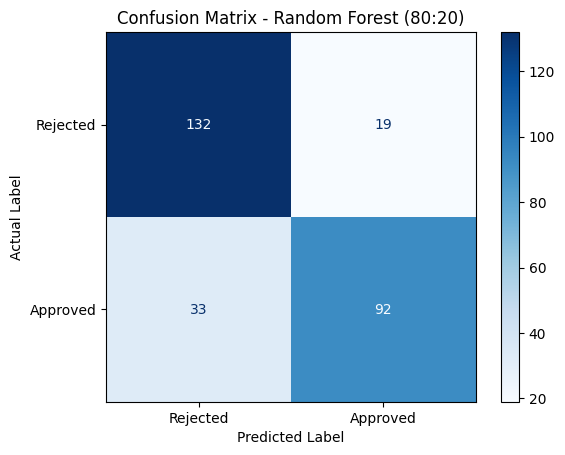

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected", "Approved"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Random Forest (80:20)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


In [ ]:
X_train.shape

(414, 22)

# **6. ANN**

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam, SGD

In [ ]:
neurons = [(8,4), (16,8), (32,16), (64,32)]
dropouts = [0.2, 0.3, 0.4]
learning_rates = [0.0001, 0.001]
batch_sizes = [32, 64]
optimizers = ['Adam', 'SGD']

In [ ]:
from tensorflow.keras.optimizers import Adam, SGD

def create_ann(neurons1, neurons2, dropout, learning_rate, optimizer_name):

    if optimizer_name == 'Adam':
        optimizer = Adam(learning_rate=learning_rate)

    else:
        optimizer = SGD(learning_rate=learning_rate)

    model = Sequential([
        Input(shape=(X_train.shape[1],)),

        Dense(neurons1, activation='relu'),
        Dropout(dropout),

        Dense(neurons2, activation='relu'),
        Dropout(dropout),

        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [ ]:
ann_results = []

for i in neurons:
    for j in dropouts:
        for k in learning_rates:
            for l in batch_sizes:
                for opt in optimizers:

                    model = create_ann(
                        i[0],
                        i[1],
                        j,
                        k,
                        opt
                    )

                    early_stop = EarlyStopping(
                        monitor='val_loss',
                        patience=5,
                        restore_best_weights=True
                    )

                    history = model.fit(
                        X_train,
                        y_train,
                        epochs=100,
                        batch_size=l,
                        validation_split=0.2,
                        callbacks=[early_stop],
                        verbose=0
                    )

                    ann_pred_prob = model.predict(
                        X_test, verbose=0
                    )

                    ann_pred = (
                        ann_pred_prob >= 0.5
                    ).astype(int).flatten()

                    ann_rejected_recall = recall_score(
                        y_test, ann_pred, pos_label=0
                    )

                    ann_approved_recall = recall_score(
                        y_test, ann_pred, pos_label=1
                    )

                    ann_business_score = (
                        0.60 * ann_rejected_recall +
                        0.40 * ann_approved_recall
                    )

                    ann_results.append({
                        'Neurons': f'{i[0]}-{i[1]}',
                        'Dropout': j,
                        'Learning Rate': k,
                        'Batch Size': l,
                        'Optimizer': opt,
                        'Rejected Recall': ann_rejected_recall * 100,
                        'Approved Recall': ann_approved_recall * 100,
                        'Business Score': ann_business_score * 100,
                        'History': history.history
                    })

# **4 Neurons Architectures × 3 Dropouts × 2 Learning Rates × 2 Batch Sizes × 2 Optmizers = 96 experiments**

In [ ]:
ann_results = pd.DataFrame(ann_results)

In [ ]:
ann_results.sort_values(
    'Business Score',
    ascending=False
).head(10)

,Neurons,Dropout,Learning Rate,Batch Size,Optimizer,Rejected Recall,Approved Recall,Business Score,History
6,8-4,0.2,0.0010,64,Adam,86.754967,84.0,85.652980,"{'accuracy': [0.5468277931213379, 0.5317220687..."
84,64-32,0.3,0.0010,32,Adam,86.754967,84.0,85.652980,"{'accuracy': [0.5981873273849487, 0.6797583103..."
52,32-16,0.2,0.0010,32,Adam,86.754967,83.2,85.332980,"{'accuracy': [0.6253776550292969, 0.7039275169..."
60,32-16,0.3,0.0010,32,Adam,86.092715,83.2,84.935629,"{'accuracy': [0.4864048361778259, 0.5619335174..."
44,16-8,0.4,0.0010,32,Adam,85.430464,84.0,84.858278,"{'accuracy': [0.5105740427970886, 0.5528700947..."
72,64-32,0.2,0.0001,32,Adam,84.768212,84.8,84.780927,"{'accuracy': [0.47129908204078674, 0.507552862..."
4,8-4,0.2,0.0010,32,Adam,85.430464,83.2,84.538278,"{'accuracy': [0.4622356593608856, 0.4531722068..."
46,16-8,0.4,0.0010,64,Adam,86.754967,80.8,84.372980,"{'accuracy': [0.5015105605125427, 0.4894259870..."
38,16-8,0.3,0.0010,64,Adam,83.443709,85.6,84.306225,"{'accuracy': [0.4864048361778259, 0.4652568101..."
54,32-16,0.2,0.0010,64,Adam,82.781457,86.4,84.228874,"{'accuracy': [0.6253776550292969, 0.6737160086..."


In [ ]:
ann_results.shape

(96, 9)

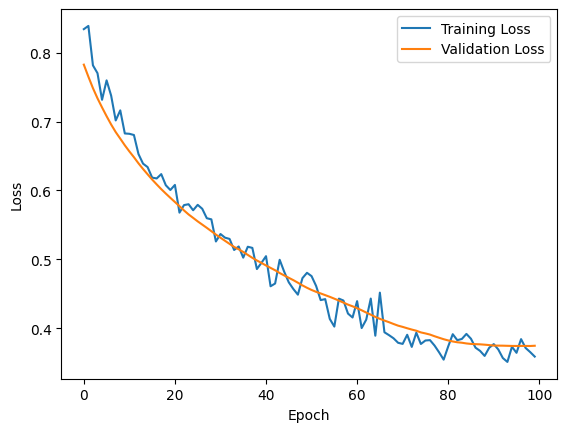

In [ ]:
best_index = ann_results['Business Score'].idxmax()
best_history = ann_results.loc[best_index, 'History']

plt.plot(best_history['loss'], label='Training Loss')
plt.plot(best_history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


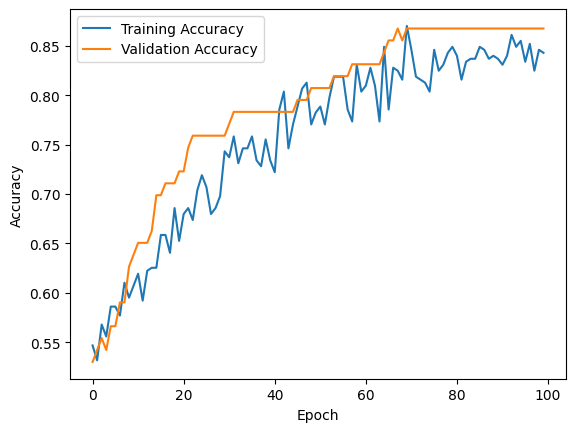

In [ ]:

plt.plot(best_history['accuracy'], label='Training Accuracy')
plt.plot(best_history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# **7. Conclusion**:



# **Practical goal is:**

Catch as many risky applicants as possible while avoiding excessive rejection of good applicants.

# **Best model based on different evaluation metrices is: "Random Forest"**

Random Forest is the best model based on different evaluation metrices. Because "Recall" becomes extremely important because we want to catch as many risky applicants as possible.

That's why we created a Buisness score column in the evaluation ( By taking 60% of Rejected Recall and 40% of Approved recall ) by prioritizing the Rejected Recall.

E.g:
Recall = 70%

That means 30 risky applicants were missed and could potentially receive credit when they shouldn't.


Since the cost of approving a risky applicant is considered higher than rejecting a good applicant, Rejected Recall was assigned a weight of 60%, while Approved Recall was assigned a weight of 40%. The Business Score was calculated as 0.60 × Rejected Recall + 0.40 × Approved Recall. The average Business Score across the evaluated train-test splits was used to compare the models.

## **Best ANN model based on different architectute is: ANN  model with ( 2 Hidden Layers, Neurons: 8-4, Dropout=0.2, Optimizer=adam, Learning Rate=0.001, Batch size=64)   and   ( 2 Hidden Layers, Neurons: 64-32, Dropout=0.3, Optimizer=adam, Learning Rate=0.001, Batch size=32) giving 85.65 Buisness Score.**

**Each Architecture took on an average of approximately 11.875 sec to complete to execution**